In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("house_prices_practice.csv")

In [3]:
df.head()

,Id,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,YearBuilt,FullBath,BedroomAbvGr,LotArea,SalePrice
0,1,7,1560,0,1658,1969,2,1,8059,177106
1,2,4,2827,2,1319,2012,3,4,13530,301044
2,3,8,3920,0,841,2010,1,4,9010,360609
3,4,5,3044,0,1058,1998,0,4,13207,240556
4,5,7,801,1,2428,2020,0,1,9117,193656


In [10]:
df.shape

(300, 10)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Id            300 non-null    int64
 1   OverallQual   300 non-null    int64
 2   GrLivArea     300 non-null    int64
 3   GarageCars    300 non-null    int64
 4   TotalBsmtSF   300 non-null    int64
 5   YearBuilt     300 non-null    int64
 6   FullBath      300 non-null    int64
 7   BedroomAbvGr  300 non-null    int64
 8   LotArea       300 non-null    int64
 9   SalePrice     300 non-null    int64
dtypes: int64(10)
memory usage: 23.6 KB


In [8]:
df.describe()

,Id,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,YearBuilt,FullBath,BedroomAbvGr,LotArea,SalePrice
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,150.500000,5.326667,2307.386667,1.330000,1468.796667,1986.163333,1.523333,2.926667,8969.453333,252262.903333
std,86.746758,2.873001,1042.561303,1.109898,672.333705,21.377089,1.131543,1.456604,3753.531132,74998.055214
min,1.000000,1.000000,504.000000,0.000000,303.000000,1950.000000,0.000000,1.000000,2009.000000,82494.000000
25%,75.750000,3.000000,1392.250000,0.000000,903.000000,1967.000000,0.000000,2.000000,5996.250000,190355.250000
50%,150.500000,5.000000,2265.500000,1.000000,1502.000000,1986.000000,2.000000,3.000000,9031.000000,251292.500000
75%,225.250000,8.000000,3306.500000,2.000000,2129.500000,2004.250000,3.000000,4.000000,12316.000000,307105.000000
max,300.000000,10.000000,3998.000000,3.000000,2492.000000,2023.000000,3.000000,5.000000,14987.000000,435291.000000


In [15]:
df.isnull().count()

Id              300
OverallQual     300
GrLivArea       300
GarageCars      300
TotalBsmtSF     300
YearBuilt       300
FullBath        300
BedroomAbvGr    300
LotArea         300
SalePrice       300
dtype: int64

In [16]:
df.isnull().sum()

Id              0
OverallQual     0
GrLivArea       0
GarageCars      0
TotalBsmtSF     0
YearBuilt       0
FullBath        0
BedroomAbvGr    0
LotArea         0
SalePrice       0
dtype: int64

In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df.corr(numeric_only=True)["SalePrice"].sort_values(ascending=False)

SalePrice       1.000000
GrLivArea       0.745095
OverallQual     0.352899
GarageCars      0.351321
FullBath        0.273731
TotalBsmtSF     0.250178
YearBuilt       0.222142
BedroomAbvGr    0.014113
Id             -0.025416
LotArea        -0.038982
Name: SalePrice, dtype: float64

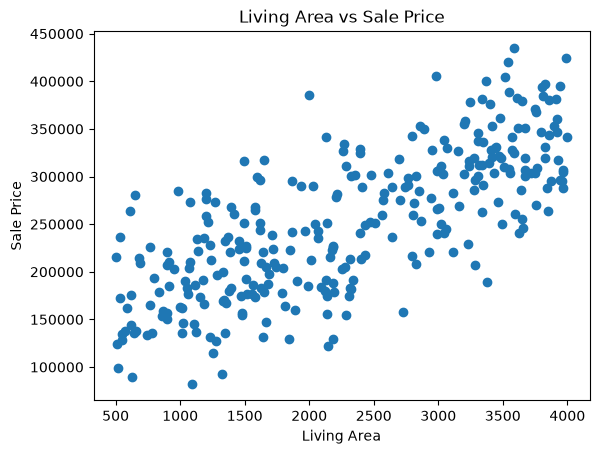

In [20]:
plt.scatter(df["GrLivArea"], df["SalePrice"])

plt.xlabel("Living Area")
plt.ylabel("Sale Price")
plt.title("Living Area vs Sale Price")

plt.show()

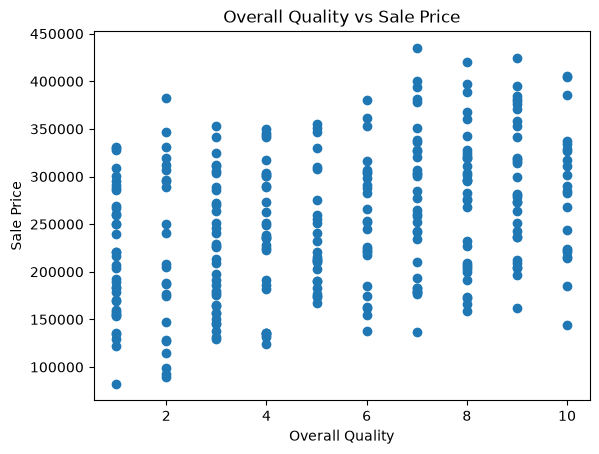

In [21]:
plt.scatter(df["OverallQual"], df["SalePrice"])

plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")
plt.title("Overall Quality vs Sale Price")

plt.show()

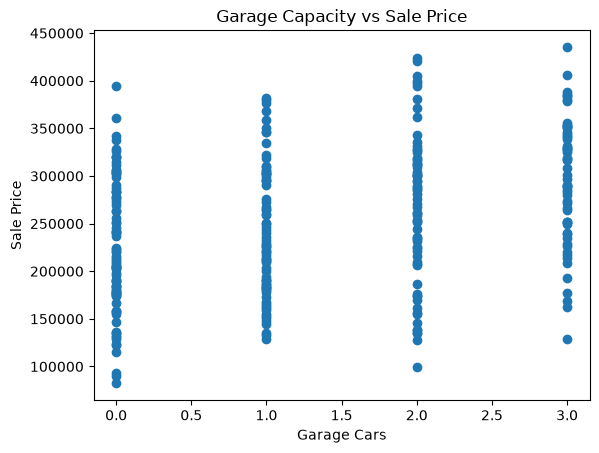

In [22]:
plt.scatter(df["GarageCars"], df["SalePrice"])

plt.xlabel("Garage Cars")
plt.ylabel("Sale Price")
plt.title("Garage Capacity vs Sale Price")

plt.show()

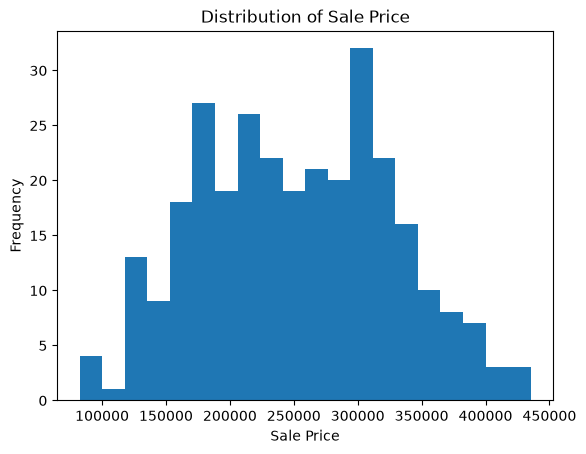

In [23]:
plt.hist(df["SalePrice"], bins=20)

plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.title("Distribution of Sale Price")

plt.show()

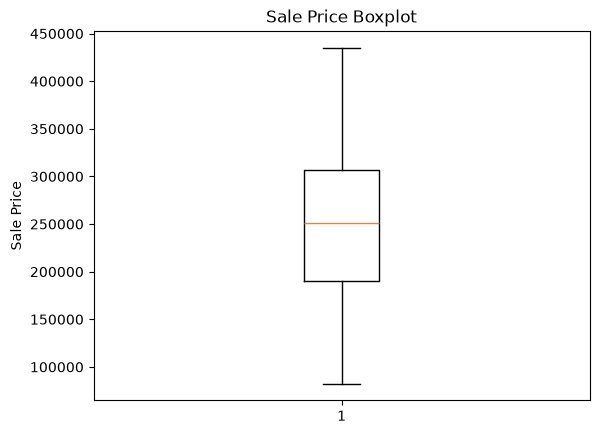

In [24]:
plt.boxplot(df["SalePrice"])

plt.ylabel("Sale Price")
plt.title("Sale Price Boxplot")

plt.show()

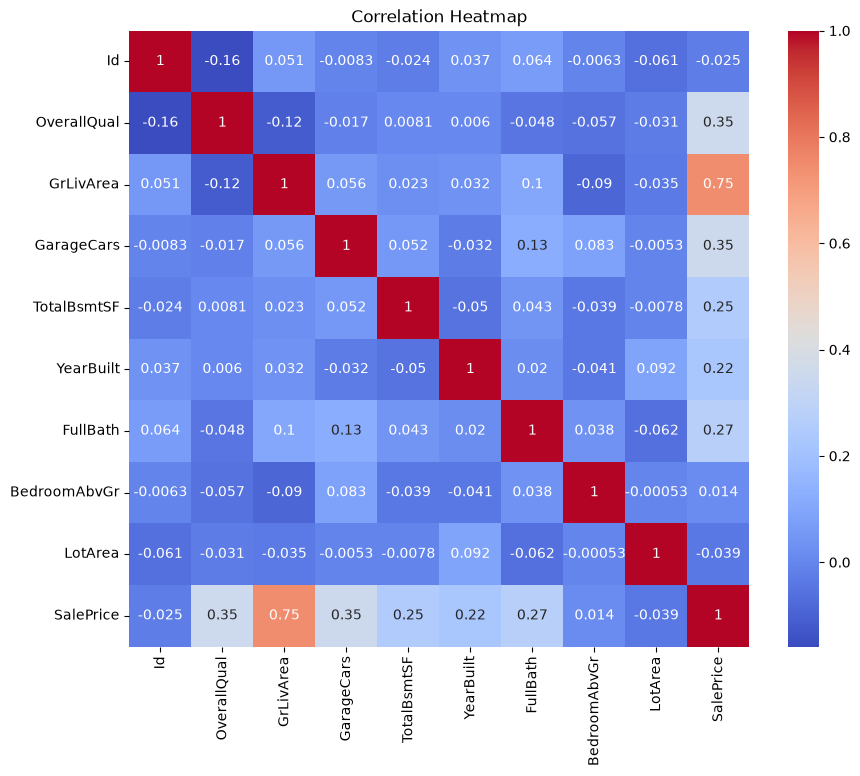

In [26]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

In [27]:
y = df["SalePrice"]

In [28]:
X = df.drop(columns=["Id", "SalePrice"])

In [29]:
X.head()

,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,YearBuilt,FullBath,BedroomAbvGr,LotArea
0,7,1560,0,1658,1969,2,1,8059
1,4,2827,2,1319,2012,3,4,13530
2,8,3920,0,841,2010,1,4,9010
3,5,3044,0,1058,1998,0,4,13207
4,7,801,1,2428,2020,0,1,9117


In [30]:
y.head()

0    177106
1    301044
2    360609
3    240556
4    193656
Name: SalePrice, dtype: int64

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [33]:
X_train.shape

(240, 8)

In [34]:
X_test.shape

(60, 8)

In [39]:
y_train.shape


(240,)

In [40]:
y_test.shape

(60,)

In [41]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[11914.69, 55.41,19109.64,...,11040.34, 4812.06, -0.16]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['OverallQual','GrLivArea','GarageCars',...,'FullBath','BedroomAbvGr', 'LotArea']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.513e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [42]:
y_pred = lr.predict(X_test)

In [43]:
y_pred[:5]

array([239161.36318914, 190489.66798468, 398000.95746315, 223169.46755224,
       135188.39570785])

In [44]:
y_test[:5]

203    224163
266    203881
152    380236
9      211664
233    122139
Name: SalePrice, dtype: int64

In [45]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 10431.655979708365


In [46]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5

print("MSE:", mse)
print("RMSE:", rmse)

MSE: 156386511.41910484
RMSE: 12505.459264621386


In [47]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R² Score:", r2)

R² Score: 0.9724369952260715


In [48]:
train_r2 = lr.score(X_train, y_train)
test_r2 = lr.score(X_test, y_test)

print("Training R²:", train_r2)
print("Testing R²:", test_r2)

Training R²: 0.97903560732947
Testing R²: 0.9724369952260715


In [49]:
for feature, coefficient in zip(X.columns, lr.coef_):
    print(feature, ":", coefficient)

print("Intercept:", lr.intercept_)

OverallQual : 11914.688135068327
GrLivArea : 55.41025707609062
GarageCars : 19109.64161433076
TotalBsmtSF : 25.199018239900507
YearBuilt : 746.3709783374918
FullBath : 11040.343045739672
BedroomAbvGr : 4812.061994479146
LotArea : -0.15952210790943155
Intercept: -1512820.5684316088


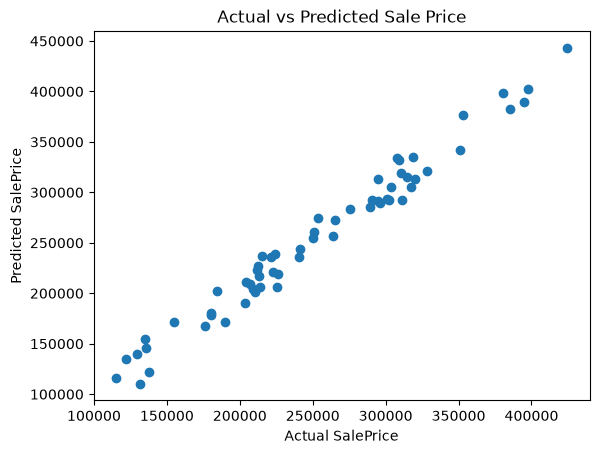

In [50]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("Actual vs Predicted Sale Price")
plt.show()

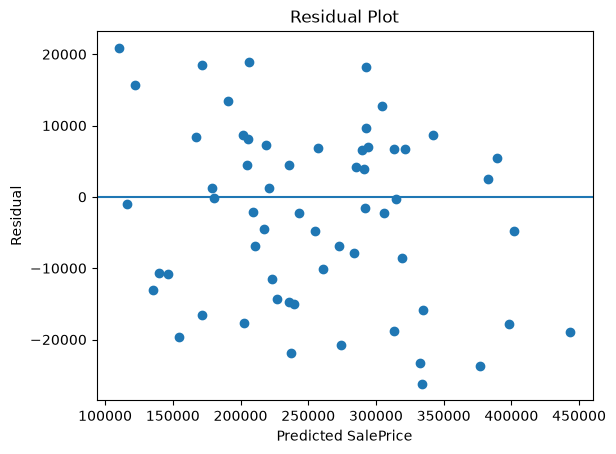

In [51]:
residuals = y_test - y_pred

plt.scatter(y_pred, residuals)
plt.axhline(y=0)
plt.xlabel("Predicted SalePrice")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.show()


In [52]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Error": y_test.values - y_pred
})

comparison.head(10)

,Actual,Predicted,Error
0,224163,239161.363189,-14998.363189
1,203881,190489.667985,13391.332015
2,380236,398000.957463,-17764.957463
3,211664,223169.467552,-11505.467552
4,122139,135188.395708,-13049.395708
5,180067,180259.039807,-192.039807
6,275810,283708.271011,-7898.271011
7,209025,204535.265477,4489.734523
8,213952,205837.941731,8114.058269
9,154885,171505.331960,-16620.331960


In [53]:
print("Multiple Linear Regression - Final Results")
print("----------------------------------------")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

Multiple Linear Regression - Final Results
----------------------------------------
MAE : 10431.655979708365
MSE : 156386511.41910484
RMSE: 12505.459264621386
R²  : 0.9724369952260715


In [ ]:
"""# Conclusion"""
"""A Multiple Linear Regression model was trained to predict house sale prices using eight numerical features.
The model achieved an MAE of approximately 10,432, an RMSE of approximately 12,505, and an R² score of 0.9724 on the test dataset.
These results indicate that the model explains a large portion of the variation in house prices while maintaining relatively low prediction errors on unseen test data.
Overall, the project demonstrated the complete workflow of a Multiple Linear Regression model, including data exploration, preprocessing, model training, prediction, and evaluation."""